In [2]:
from pathlib import Path
import pandas as pd

# Folder containing the CSV and both image folders
dataset_folder = Path(
    "/Users/benjaminquintanilla/Desktop/GEOAIPROJECT/"
    "archive/dataset_amazonia_garimpo_binario"
)

manifest_path = dataset_folder / "manifesto_chips.csv"

# Check that the required files and folders exist
required_paths = {
    "Manifest CSV": manifest_path,
    "Mining images": dataset_folder / "com_garimpo",
    "Non-mining images": dataset_folder / "sem_garimpo",
}

for name, path in required_paths.items():
    found = path.is_file() if name == "Manifest CSV" else path.is_dir()
    print(f"{name}: {'Found' if found else 'MISSING'}")

    if not found:
        raise FileNotFoundError(f"Could not find: {path}")

# Load the metadata without changing the original CSV
manifest = pd.read_csv(manifest_path)

print(f"\nTotal images listed: {len(manifest):,}")

display(
    manifest.groupby(["label_str", "label_int"])
    .size()
    .reset_index(name="image_count")
)

display(manifest.head())

Manifest CSV: Found
Mining images: Found
Non-mining images: Found

Total images listed: 111,584


,label_str,label_int,image_count
0,com_garimpo,1,55541
1,sem_garimpo,0,56043


,png_path,tif_source,label_str,label_int,tile_row,tile_col,tile_size_px,utm_epsg,overlap_area_m2,overlap_ratio,...,ymax,centroid_lon,centroid_lat,crs_raster,transform,width_px,height_px,bands_used,dtype_src,nodata
0,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,v3_new_ret_s2_median_2024_dry-0000000000-00000...,sem_garimpo,0,0,0,128,32721,0.0,0.0,...,-4.495799,-58.332911,-4.501548,EPSG:4326,"(8.983152841195215e-05, 0.0, -58.3386606758752...",13568,13568,"['B4', 'B3', 'B2']",float32,NaN
1,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,v3_new_ret_s2_median_2024_dry-0000000000-00000...,sem_garimpo,0,0,1,128,32721,0.0,0.0,...,-4.495799,-58.321413,-4.501548,EPSG:4326,"(8.983152841195215e-05, 0.0, -58.3386606758752...",13568,13568,"['B4', 'B3', 'B2']",float32,NaN
2,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,v3_new_ret_s2_median_2024_dry-0000000000-00000...,sem_garimpo,0,0,2,128,32721,0.0,0.0,...,-4.495799,-58.309915,-4.501548,EPSG:4326,"(8.983152841195215e-05, 0.0, -58.3386606758752...",13568,13568,"['B4', 'B3', 'B2']",float32,NaN
3,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,v3_new_ret_s2_median_2024_dry-0000000000-00000...,sem_garimpo,0,0,3,128,32721,0.0,0.0,...,-4.495799,-58.298416,-4.501548,EPSG:4326,"(8.983152841195215e-05, 0.0, -58.3386606758752...",13568,13568,"['B4', 'B3', 'B2']",float32,NaN
4,sem_garimpo/v3_new_ret_s2_median_2024_dry-0000...,v3_new_ret_s2_median_2024_dry-0000000000-00000...,sem_garimpo,0,0,4,128,32721,0.0,0.0,...,-4.495799,-58.286918,-4.501548,EPSG:4326,"(8.983152841195215e-05, 0.0, -58.3386606758752...",13568,13568,"['B4', 'B3', 'B2']",float32,NaN


In [3]:
# Check for missing paths and repeated image entries
missing_paths = manifest["png_path"].isna()
duplicate_paths = manifest["png_path"].duplicated(keep=False)

# Check that class names match numeric labels
expected_labels = {"sem_garimpo": 0, "com_garimpo": 1}
expected = manifest["label_str"].map(expected_labels)

label_errors = expected.isna() | manifest["label_int"].ne(expected)

# Check that each image's folder matches its class label
folder_labels = manifest["png_path"].fillna("").map(
    lambda value: Path(value).parent.name
)
folder_errors = folder_labels.ne(manifest["label_str"])

# Check that every listed image exists on your computer
print("Checking image paths...")

file_exists = manifest["png_path"].map(
    lambda value: (
        (dataset_folder / value).is_file()
        if isinstance(value, str) and value.strip()
        else False
    )
)

print(f"\nImages listed: {len(manifest):,}")
print(f"Files found: {file_exists.sum():,}")
print(f"Files missing: {(~file_exists).sum():,}")
print(f"Rows with empty paths: {missing_paths.sum():,}")
print(f"Rows with duplicate paths: {duplicate_paths.sum():,}")
print(f"Label errors: {label_errors.sum():,}")
print(f"Folder/label mismatches: {folder_errors.sum():,}")

# Display any entries that need attention
problem_rows = (
    ~file_exists
    | duplicate_paths
    | label_errors
    | folder_errors
)

if problem_rows.any():
    display(
        manifest.loc[
            problem_rows,
            ["png_path", "label_str", "label_int"]
        ].head(10)
    )
else:
    print("\nAll image paths and labels passed these checks.")

Checking image paths...

Images listed: 111,584
Files found: 111,584
Files missing: 0
Rows with empty paths: 0
Rows with duplicate paths: 0
Label errors: 0
Folder/label mismatches: 0

All image paths and labels passed these checks.


In [ ]:
from PIL import Image
from collections import Counter

image_formats = Counter()
image_issues = []

print("Checking image readability, dimensions, and color modes...")

for number, relative_path in enumerate(manifest["png_path"], start=1):
    image_path = dataset_folder / relative_path

    try:
        with Image.open(image_path) as image:
            image.load()  # Read the pixels to check for decoding errors

            width, height = image.size
            mode = image.mode

            image_formats[(width, height, mode)] += 1

            if (width, height) != (128, 128) or mode != "RGB":
                image_issues.append({
                    "png_path": relative_path,
                    "issue": "Unexpected dimensions or color mode",
                    "width": width,
                    "height": height,
                    "mode": mode,
                })

    except Exception as error:
        image_issues.append({
            "png_path": relative_path,
            "issue": f"{type(error).__name__}: {error}",
            "width": None,
            "height": None,
            "mode": None,
        })

    if number % 10_000 == 0 or number == len(manifest):
        print(f"Checked {number:,} / {len(manifest):,}")

format_summary = pd.DataFrame(
    [
        {
            "width": width,
            "height": height,
            "mode": mode,
            "image_count": count,
        }
        for (width, height, mode), count in image_formats.items()
    ]
)

image_issues_df = pd.DataFrame(
    image_issues,
    columns=["png_path", "issue", "width", "height", "mode"]
)

print("\nImage format summary:")
display(format_summary)

print(f"Images needing review: {len(image_issues_df):,}")

if not image_issues_df.empty:
    display(image_issues_df.head(10))
else:
    print("All images decoded successfully and are 128 × 128 RGB.")

In [ ]:
# come back to above cell

In [7]:
from PIL import Image
from collections import Counter

# Sample 500 images per class
sample = (
    manifest.groupby("label_int", group_keys=False)
    .sample(n=500, random_state=42)
)

image_formats = Counter()
image_issues = []

for number, relative_path in enumerate(sample["png_path"], start=1):
    try:
        with Image.open(dataset_folder / relative_path) as image:
            image.load()

            width, height = image.size
            mode = image.mode
            image_formats[(width, height, mode)] += 1

            if (width, height) != (128, 128) or mode != "RGB":
                image_issues.append({
                    "png_path": relative_path,
                    "issue": f"Size: {image.size}, mode: {mode}",
                })

    except Exception as error:
        image_issues.append({
            "png_path": relative_path,
            "issue": f"{type(error).__name__}: {error}",
        })

    if number % 100 == 0:
        print(f"Checked {number:,} / {len(sample):,}", flush=True)

display(pd.DataFrame([
    {"width": w, "height": h, "mode": mode, "count": count}
    for (w, h, mode), count in image_formats.items()
]))

print(f"Sampled images needing review: {len(image_issues):,}")

if image_issues:
    display(pd.DataFrame(image_issues).head(10))

Checked 100 / 1,000
Checked 200 / 1,000
Checked 300 / 1,000
Checked 400 / 1,000
Checked 500 / 1,000
Checked 600 / 1,000
Checked 700 / 1,000
Checked 800 / 1,000
Checked 900 / 1,000
Checked 1,000 / 1,000


,width,height,mode,count
0,128,128,RGB,1000


Sampled images needing review: 0


In [8]:
# Preserve the original overlap values and labels
manifest["overlap_above_one"] = manifest["overlap_ratio"] > 1

print(
    "Images with overlap ratio above 1:",
    f"{manifest['overlap_above_one'].sum():,}"
)

# Check whether the labels follow a 5% overlap threshold
expected_from_overlap = (
    manifest["overlap_ratio"] >= 0.05
).astype(int)

print(
    "Labels inconsistent with a 5% threshold:",
    f"{manifest['label_int'].ne(expected_from_overlap).sum():,}"
)

# Summarize class balance and geographic extent per source raster
source_summary = (
    manifest.groupby("tif_source")
    .agg(
        images=("png_path", "size"),
        mining_images=("label_int", "sum"),
        west=("xmin", "min"),
        south=("ymin", "min"),
        east=("xmax", "max"),
        north=("ymax", "max"),
        overlap_flags=("overlap_above_one", "sum"),
    )
    .reset_index()
)

source_summary["non_mining_images"] = (
    source_summary["images"] - source_summary["mining_images"]
)

source_summary["mining_pct"] = (
    100 * source_summary["mining_images"] / source_summary["images"]
).round(2)

# Short IDs make the source areas easier to discuss
source_summary.insert(
    0, "source_id", range(1, len(source_summary) + 1)
)

display(
    source_summary[
        [
            "source_id", "images",
            "mining_images", "non_mining_images", "mining_pct",
            "west", "south", "east", "north", "overlap_flags",
        ]
    ].round(4)
)


Images with overlap ratio above 1: 12,836
Labels inconsistent with a 5% threshold: 0


,source_id,images,mining_images,non_mining_images,mining_pct,west,south,east,north,overlap_flags
0,1,11236,5229,6007,46.54,-58.3387,-5.7146,-57.1198,-4.4958,964
1,2,11236,6705,4531,59.67,-57.1198,-5.7146,-55.9010,-4.4958,1229
2,3,11130,2618,8512,23.52,-55.9010,-5.7146,-54.6937,-4.4958,407
3,4,11236,6493,4743,57.79,-58.3387,-6.9335,-57.1198,-5.7146,1460
4,5,11236,10025,1211,89.22,-57.1198,-6.9335,-55.9010,-5.7146,3091
5,6,11130,6117,5013,54.96,-55.9010,-6.9335,-54.6937,-5.7146,1496
6,7,11236,673,10563,5.99,-58.3387,-8.1523,-57.1198,-6.9335,66
7,8,11236,6371,4865,56.70,-57.1198,-8.1523,-55.9010,-6.9335,1518
8,9,11130,9132,1998,82.05,-55.9010,-8.1523,-54.6937,-6.9335,2263
9,10,3604,18,3586,0.50,-58.3387,-8.5432,-57.1198,-8.1523,0


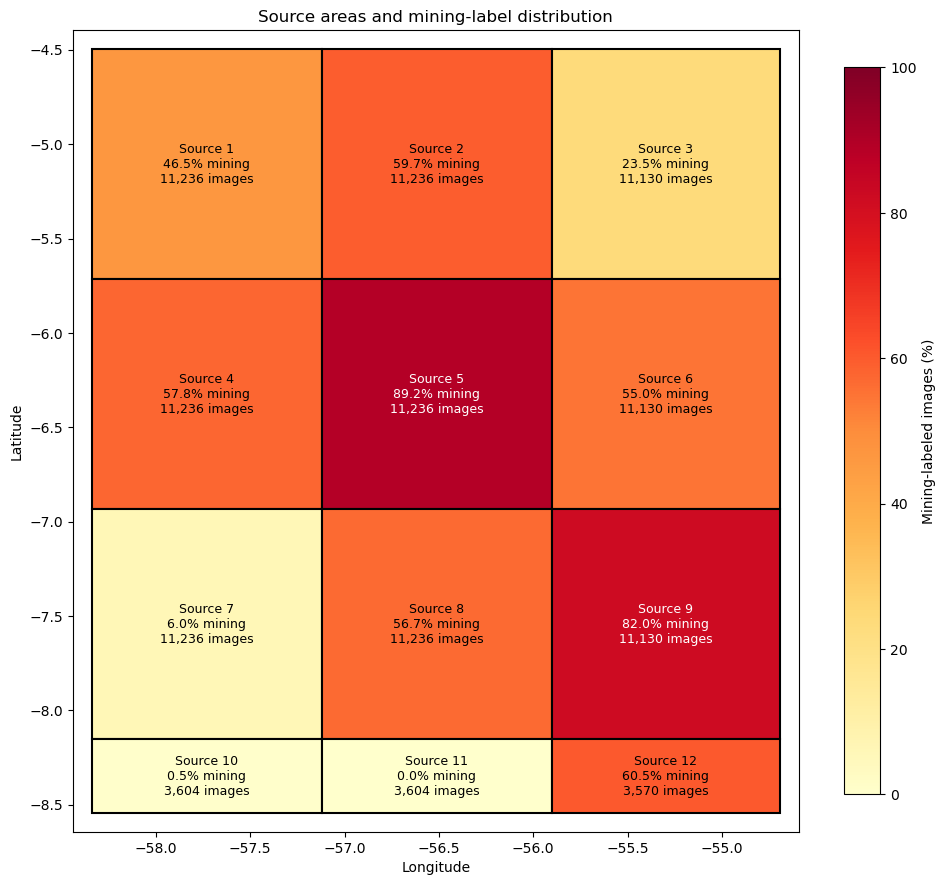

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

fig, ax = plt.subplots(figsize=(10, 10))

# Color represents the percentage of mining-labeled images
cmap = plt.get_cmap("YlOrRd")
norm = Normalize(vmin=0, vmax=100)

for _, row in source_summary.iterrows():
    rectangle = Rectangle(
        (row["west"], row["south"]),
        row["east"] - row["west"],
        row["north"] - row["south"],
        facecolor=cmap(norm(row["mining_pct"])),
        edgecolor="black",
        linewidth=1.5,
    )
    ax.add_patch(rectangle)

    center_lon = (row["west"] + row["east"]) / 2
    center_lat = (row["south"] + row["north"]) / 2

    ax.text(
        center_lon,
        center_lat,
        f"Source {int(row['source_id'])}\n"
        f"{row['mining_pct']:.1f}% mining\n"
        f"{int(row['images']):,} images",
        ha="center",
        va="center",
        fontsize=9,
        color="white" if row["mining_pct"] >= 65 else "black",
    )

ax.set_xlim(
    source_summary["west"].min() - 0.1,
    source_summary["east"].max() + 0.1,
)
ax.set_ylim(
    source_summary["south"].min() - 0.1,
    source_summary["north"].max() + 0.1,
)

ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Source areas and mining-label distribution")

fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    label="Mining-labeled images (%)",
    shrink=0.75,
)

plt.tight_layout()
plt.show()

In [10]:
# Attach the source IDs from our summary to each image
source_id_lookup = source_summary.set_index("tif_source")["source_id"]
manifest["source_id"] = manifest["tif_source"].map(source_id_lookup)

split_mapping = {
    1: "test",
    2: "test",
    3: "validation",
    **{source_id: "train" for source_id in range(4, 13)},
}

manifest["split"] = manifest["source_id"].map(split_mapping)

# Confirm every image received an assignment
assert manifest["source_id"].notna().all(), "Some source IDs are missing."
assert manifest["split"].notna().all(), "Some split assignments are missing."

# Confirm each source belongs to only one split
assert (
    manifest.groupby("source_id")["split"].nunique() == 1
).all(), "A source appears in multiple splits."

split_summary = (
    manifest.groupby("split")
    .agg(
        images=("png_path", "size"),
        mining_images=("label_int", "sum"),
        source_count=("source_id", "nunique"),
    )
    .reindex(["train", "validation", "test"])
)

split_summary["non_mining_images"] = (
    split_summary["images"] - split_summary["mining_images"]
)

split_summary["dataset_pct"] = (
    100 * split_summary["images"] / len(manifest)
).round(2)

split_summary["mining_pct"] = (
    100 * split_summary["mining_images"] / split_summary["images"]
).round(2)

assert (
    (split_summary["mining_images"] > 0)
    & (split_summary["non_mining_images"] > 0)
).all(), "A split is missing one class."

display(
    split_summary[
        [
            "images", "dataset_pct", "source_count",
            "mining_images", "non_mining_images", "mining_pct",
        ]
    ]
)

,images,dataset_pct,source_count,mining_images,non_mining_images,mining_pct
split,,,,,,
train,77982,69.89,9,40989,36993,52.56
validation,11130,9.97,1,2618,8512,23.52
test,22472,20.14,2,11934,10538,53.11


In [11]:
# Flag one row/column of chips along boundaries between splits
train_boundary = (
    manifest["split"].eq("train")
    & manifest["source_id"].isin([4, 5, 6])
    & manifest["tile_row"].eq(0)
)

validation_boundary = (
    manifest["split"].eq("validation")
    & manifest["source_id"].eq(3)
    & manifest["tile_col"].eq(0)
)

manifest["buffer_excluded"] = train_boundary | validation_boundary

# Use this table for model preparation from now on
model_manifest = manifest.loc[
    ~manifest["buffer_excluded"]
].copy()

print(f"Chips excluded for separation: {manifest['buffer_excluded'].sum():,}")
print(f"Images retained: {len(model_manifest):,}")

# Summarize the retained data
buffered_summary = (
    model_manifest.groupby("split")
    .agg(
        images=("png_path", "size"),
        mining_images=("label_int", "sum"),
    )
    .reindex(["train", "validation", "test"])
)

buffered_summary["non_mining_images"] = (
    buffered_summary["images"] - buffered_summary["mining_images"]
)

buffered_summary["mining_pct"] = (
    100
    * buffered_summary["mining_images"]
    / buffered_summary["images"]
).round(2)

assert (
    (buffered_summary["mining_images"] > 0)
    & (buffered_summary["non_mining_images"] > 0)
).all(), "A split is missing one class."

# Check separation using actual chip bounds, in degrees
train_north = model_manifest.loc[
    model_manifest["split"].eq("train"), "ymax"
].max()

evaluation_south = model_manifest.loc[
    model_manifest["split"].isin(["validation", "test"]), "ymin"
].min()

test_east = model_manifest.loc[
    model_manifest["split"].eq("test"), "xmax"
].max()

validation_west = model_manifest.loc[
    model_manifest["split"].eq("validation"), "xmin"
].min()

assert train_north < evaluation_south, "No north/south gap found."
assert test_east < validation_west, "No test/validation gap found."

print("\nGeographic gaps verified from chip bounds.")
display(buffered_summary)

Chips excluded for separation: 423
Images retained: 111,161

Geographic gaps verified from chip bounds.


,images,mining_images,non_mining_images,mining_pct
split,,,,
train,77665,40799,36866,52.53
validation,11024,2526,8498,22.91
test,22472,11934,10538,53.11


In [12]:
import numpy as np
from PIL import Image

def iter_batches(split_name, batch_size=32, shuffle=None, seed=42):
    """Load batches of images and labels for one dataset split."""

    if split_name not in {"train", "validation", "test"}:
        raise ValueError("Choose 'train', 'validation', or 'test'.")

    if batch_size < 1:
        raise ValueError("batch_size must be at least 1.")

    # Shuffle training by default; keep evaluation order fixed
    if shuffle is None:
        shuffle = split_name == "train"

    records = (
        model_manifest.loc[
            model_manifest["split"].eq(split_name),
            ["png_path", "label_int"]
        ]
        .reset_index(drop=True)
    )

    if records.empty:
        raise ValueError(f"No images found for split: {split_name}")

    order = np.arange(len(records))

    if shuffle:
        rng = np.random.default_rng(seed)
        rng.shuffle(order)

    for start in range(0, len(order), batch_size):
        batch_rows = records.iloc[order[start:start + batch_size]]

        images = []

        for relative_path in batch_rows["png_path"]:
            with Image.open(dataset_folder / relative_path) as image:
                # Stop if an unchecked image has an unexpected format
                if image.size != (128, 128) or image.mode != "RGB":
                    raise ValueError(
                        f"Unexpected image format: {relative_path} "
                        f"— size={image.size}, mode={image.mode}"
                    )

                pixels = np.array(image)

                if pixels.dtype != np.uint8:
                    raise ValueError(
                        f"Expected uint8 pixels: {relative_path}"
                    )

                images.append(pixels.astype(np.float32) / 255.0)

        X_batch = np.stack(images)
        y_batch = batch_rows["label_int"].to_numpy(dtype=np.int64)

        yield X_batch, y_batch


# Test one training batch
X_batch, y_batch = next(iter_batches("train", batch_size=32))

print("Image batch shape:", X_batch.shape)
print("Label batch shape:", y_batch.shape)
print("Image data type:", X_batch.dtype)
print("Pixel range:", float(X_batch.min()), "to", float(X_batch.max()))
print("Labels:", y_batch)

assert X_batch.shape == (32, 128, 128, 3)
assert y_batch.shape == (32,)
assert np.isin(y_batch, [0, 1]).all()

print("\nFirst batch loaded successfully.")

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Image data type: float32
Pixel range: 0.0 to 1.0
Labels: [0 1 1 1 0 0 1 1 1 0 0 1 0 0 0 1 0 0 1 0 0 0 1 0 0 1 0 1 1 0 0 1]

First batch loaded successfully.


In [13]:
# Save preparation outputs in a separate folder
output_folder = dataset_folder / "prepared_data"
output_folder.mkdir(exist_ok=True)

# Full record, including excluded boundary chips and overlap flags
manifest.to_csv(
    output_folder / "manifest_with_quality_flags.csv",
    index=False
)

# Retained images only
model_manifest.to_csv(
    output_folder / "model_manifest.csv",
    index=False
)

# Separate manifests for each split
for split_name in ["train", "validation", "test"]:
    split_rows = model_manifest.loc[
        model_manifest["split"].eq(split_name)
    ]

    split_rows.to_csv(
        output_folder / f"{split_name}_manifest.csv",
        index=False
    )

    print(f"Saved {split_name}: {len(split_rows):,} images")

# Save source information and final split counts
source_summary.to_csv(
    output_folder / "source_summary.csv",
    index=False
)

buffered_summary.to_csv(
    output_folder / "split_summary.csv",
    index=True
)

print(f"\nOutputs saved to:\n{output_folder}")

Saved train: 77,665 images
Saved validation: 11,024 images
Saved test: 22,472 images

Outputs saved to:
/Users/benjaminquintanilla/Desktop/GEOAIPROJECT/archive/dataset_amazonia_garimpo_binario/prepared_data
